# Known examples

The first pair of Mapper graphs attains the bound $d_{FD}\leq 3d_I$. For the second pair, we compare the ILP result with hand-built maps that approach the optimum. We then add a branch to a Mapper graph and see where the recovered maps attain their largest distance distortion.

Each plot shows the source graph on the left and its image on the right. Matching colors trace the same arcs. Scores are in grid units and displayed to three decimal places.

In [1]:
import sys
from fractions import Fraction
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
from cereeberus import Interleave
from pulp import PULP_CBC_CMD

if Path.cwd().name == "experiments":
    sys.path.insert(0, str(Path.cwd().parent))

from core.distortion import functional_distortion
from core.fd_map_build import maps_from_interleave, validate_interleaving
from core.functionaldistortiongraph import E, FunctionalDistortionGraph
from visualize.fd_metromaps import draw_fd_maps


def report(label, F, G, Phi, Psi, preprocessing, construction):
    """Print scores and timings for both maps, and return the evaluation result."""
    start = perf_counter()
    result = functional_distortion(F, G, Phi, Psi)
    evaluation = perf_counter() - start
    total = preprocessing + construction + evaluation
    print(
        f"{label} — Elapsed time: total {total:.3f} s "
        f"(preprocessing: {preprocessing:.3f} s, FD map construction: {construction:.3f} s, "
        f"distortion computation: {evaluation:.3f} s)"
    )
    print(
        f"Height Φ = {result['height_Phi_units']:.3f} | Height Ψ = {result['height_Psi_units']:.3f} | "
        f"D = {result['D_units']:.3f} | FD = {result['FD_units']:.3f}"
    )
    return result



def recover_maps(make_pair):
    """Fit the MapperGraph pair from make_pair and time map recovery."""
    start = perf_counter()
    F, G = make_pair()
    interleaving = Interleave(F, G)
    solver = PULP_CBC_CMD(msg=False, threads=1, options=["randomSeed 1", "randomCbcSeed 1"])
    interleaving.fit(pulp_solver=solver)
    preprocessing = perf_counter() - start

    start = perf_counter()
    maps = maps_from_interleave(interleaving, seed=0)
    construction = perf_counter() - start
    return interleaving, maps, preprocessing, construction


## Graph construction

We join labeled intervals at shared heights and place a vertex at every integer height. For the second pair, the height range of $G$ is one unit lower than that of $F$.

In [ ]:
def glued_intervals(intervals, identifications):
    """Subdivide labeled intervals and identify the specified endpoints."""
    representatives = dict(identifications)
    heights, edges = {}, []
    for branch, lo, hi in intervals:
        path = [representatives.get((branch, t), (branch, t)) for t in range(lo, hi + 1)]
        heights.update((vertex, vertex[1]) for vertex in path)
        edges.extend(zip(path, path[1:]))
    return FunctionalDistortionGraph.from_edges(heights, edges).mapper


def known_pair(T=9, *, factor_three):
    """Build one of the two Mapper pairs with tails cut off at T."""
    f_intervals = [("F1", 1, T), ("F2", 1, 3), ("F3", -T, T)]
    f_joins = [(("F2", 1), ("F1", 1)), (("F2", 3), ("F3", 3))]
    # Shift the height range of G for the second pair.
    shift = 0 if factor_three else 1
    g_intervals = [("G1", 0, T - shift), ("G2", -T - shift, T - shift)]
    g_joins = [(("G1", 0), ("G2", 0))]
    if factor_three:
        f_intervals += [("F4", -T, -1), ("F5", -3, -1)]
        f_joins += [(("F5", -1), ("F4", -1)), (("F5", -3), ("F3", -3))]
        g_intervals += [("G3", -T, 0)]
        g_joins += [(("G3", 0), ("G2", 0))]
    return glued_intervals(f_intervals, f_joins), glued_intervals(g_intervals, g_joins)




def plot_known_maps(maps, title):
    """Draw both directions using straight segments and short vertex labels."""
    def horizontal_position(branch, height):
        if branch == "G1":
            return -min(height, 3)
        if branch == "G3":
            return min(-height, 3)
        return {"F1": -3, "F2": -1.5, "F3": 0, "F4": 3, "F5": 1.5, "G2": 0}[branch]

    positions, labels = {}, {}
    for name in ("F", "G"):
        graph = maps[name]
        positions[name] = {vertex: (horizontal_position(vertex[0], height), height)
                           for vertex, height in graph.f.items()}
        for i, vertex in enumerate(sorted(graph.f, key=lambda v: (graph.f[v], v[0]))):
            labels[vertex] = f"{name.lower()}{i}"

    fig = draw_fd_maps(
        maps["Phi"], maps["Psi"], posF=positions["F"], posG=positions["G"],
        vertex_label=labels.__getitem__, figsize=(14, 15),
        show_vertmaps=False, show_breakpoints=False,
    )
    fig.suptitle(title)
    plt.show()


## Factor-three pair

The side branches of $F$ join the spine at heights $-3$ and $3$. The branches of $G$ meet at height $0$. We test two cutoffs, $T=9$ and $T=11$, and draw the recovered maps for $T=9$.

Factor three (ILP, T=9, n=1) — Elapsed time: total 1.405 s (preprocessing: 1.290 s, FD map construction: 0.061 s, distortion computation: 0.053 s)
Height Φ = 1.000 | Height Ψ = 1.000 | D = 3.000 | FD = 3.000
Factor three (ILP, T=11, n=1) — Elapsed time: total 1.291 s (preprocessing: 1.160 s, FD map construction: 0.072 s, distortion computation: 0.059 s)
Height Φ = 1.000 | Height Ψ = 1.000 | D = 3.000 | FD = 3.000


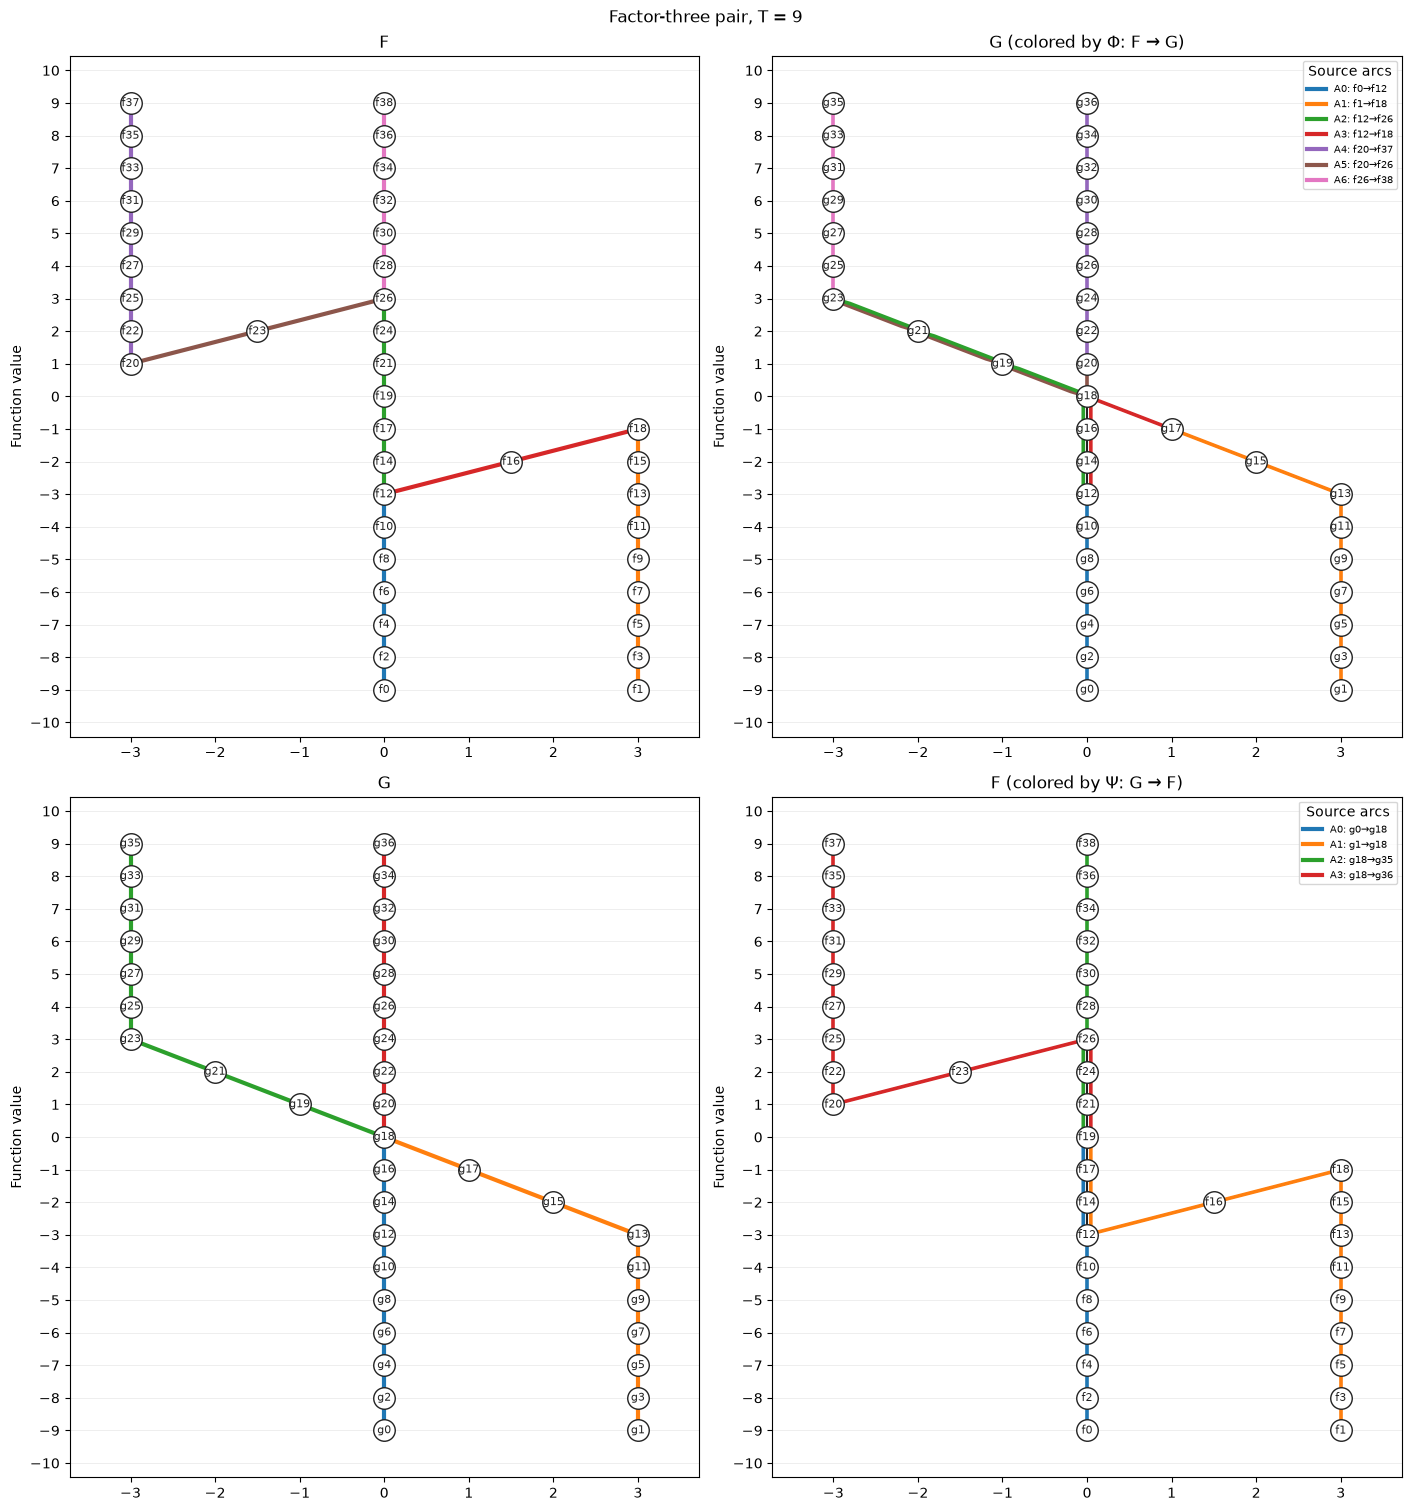

In [ ]:
for T in (9, 11):
    interleaving, maps, preprocessing, construction = recover_maps(
        lambda: known_pair(T, factor_three=True)
    )
    report(f"Factor three (ILP, T={T}, n={interleaving.n})",
           maps["F"], maps["G"], maps["Phi"], maps["Psi"], preprocessing, construction)
    if T == 9:
        factor_fit, factor_maps = interleaving, maps

plot_known_maps(factor_maps, "Factor-three pair, T = 9")


In [4]:
try:
    validate_interleaving(factor_fit.assignment)
except ValueError as error:
    print(f"Strict validation of the returned ILP matrices: {error}")
else:
    print("Strict validation passed.")


Strict validation of the returned ILP matrices: phi[n][V]: ('reeb_auto', 0) must have exactly one image at level -10


ceREEBerus 0.2.0 can leave columns blank at the outer levels of the smoothed maps. The check above tests the returned matrices. The construction below gives a full 1-interleaving for this pair.

### Why the ratio is three

Suppose both height errors and $D$ are below $3$. The images of the two upper tips of $F$ lie above $T-3$. If they lie on the same branch of $G$, the lower image is attained on both upper tails of $F$. The tails start at height at most $3$, so their starting images lie below $6$. The path between the two preimages reaches both $3$ and $T$, so $D\geq (T-3)/2\geq 3$. Thus the two tips map to different branches, and the path between them has a preimage of the junction at height $0$. That preimage has height below $3$, so it lies on the upper side branch. Reflection gives another preimage on the lower side branch. Their path spans at least $[-3,3]$, giving $D\geq 3$.

For a 1-interleaving, send $F_1$ to the upper side branch of $U_1G$ and send $F_2,F_3$ to its spine. In the reverse direction, send $G_1$ to the spine of $U_1F$ up to height $2$ and to its upper side branch above that. Reflect both maps below height $0$. The composites agree with the canonical maps because $U_2G$ merges the upper branches through height $2$, and $U_2F$ merges the upper hook with the spine on $[1,3]$. The tails match at equal heights up to the cutoffs.

The graphs have different branch structures, so $d_I=1$ on the integer subdivisions. The lower bound and $d_{FD}\leq 3d_I$ give $d_{FD}=3$ for the realizations.

## Mapper graphs with shifted height ranges

The minimum and maximum heights differ by one between $F$ and $G$. This gives $d_{FD}\geq 1$. We compare the maps recovered from the ILP with two hand-built map pairs.

Shifted Mapper pair (ILP, n=1) — Elapsed time: total 0.822 s (preprocessing: 0.448 s, FD map construction: 0.048 s, distortion computation: 0.327 s)
Height Φ = 1.000 | Height Ψ = 1.000 | D = 1.500 | FD = 1.500


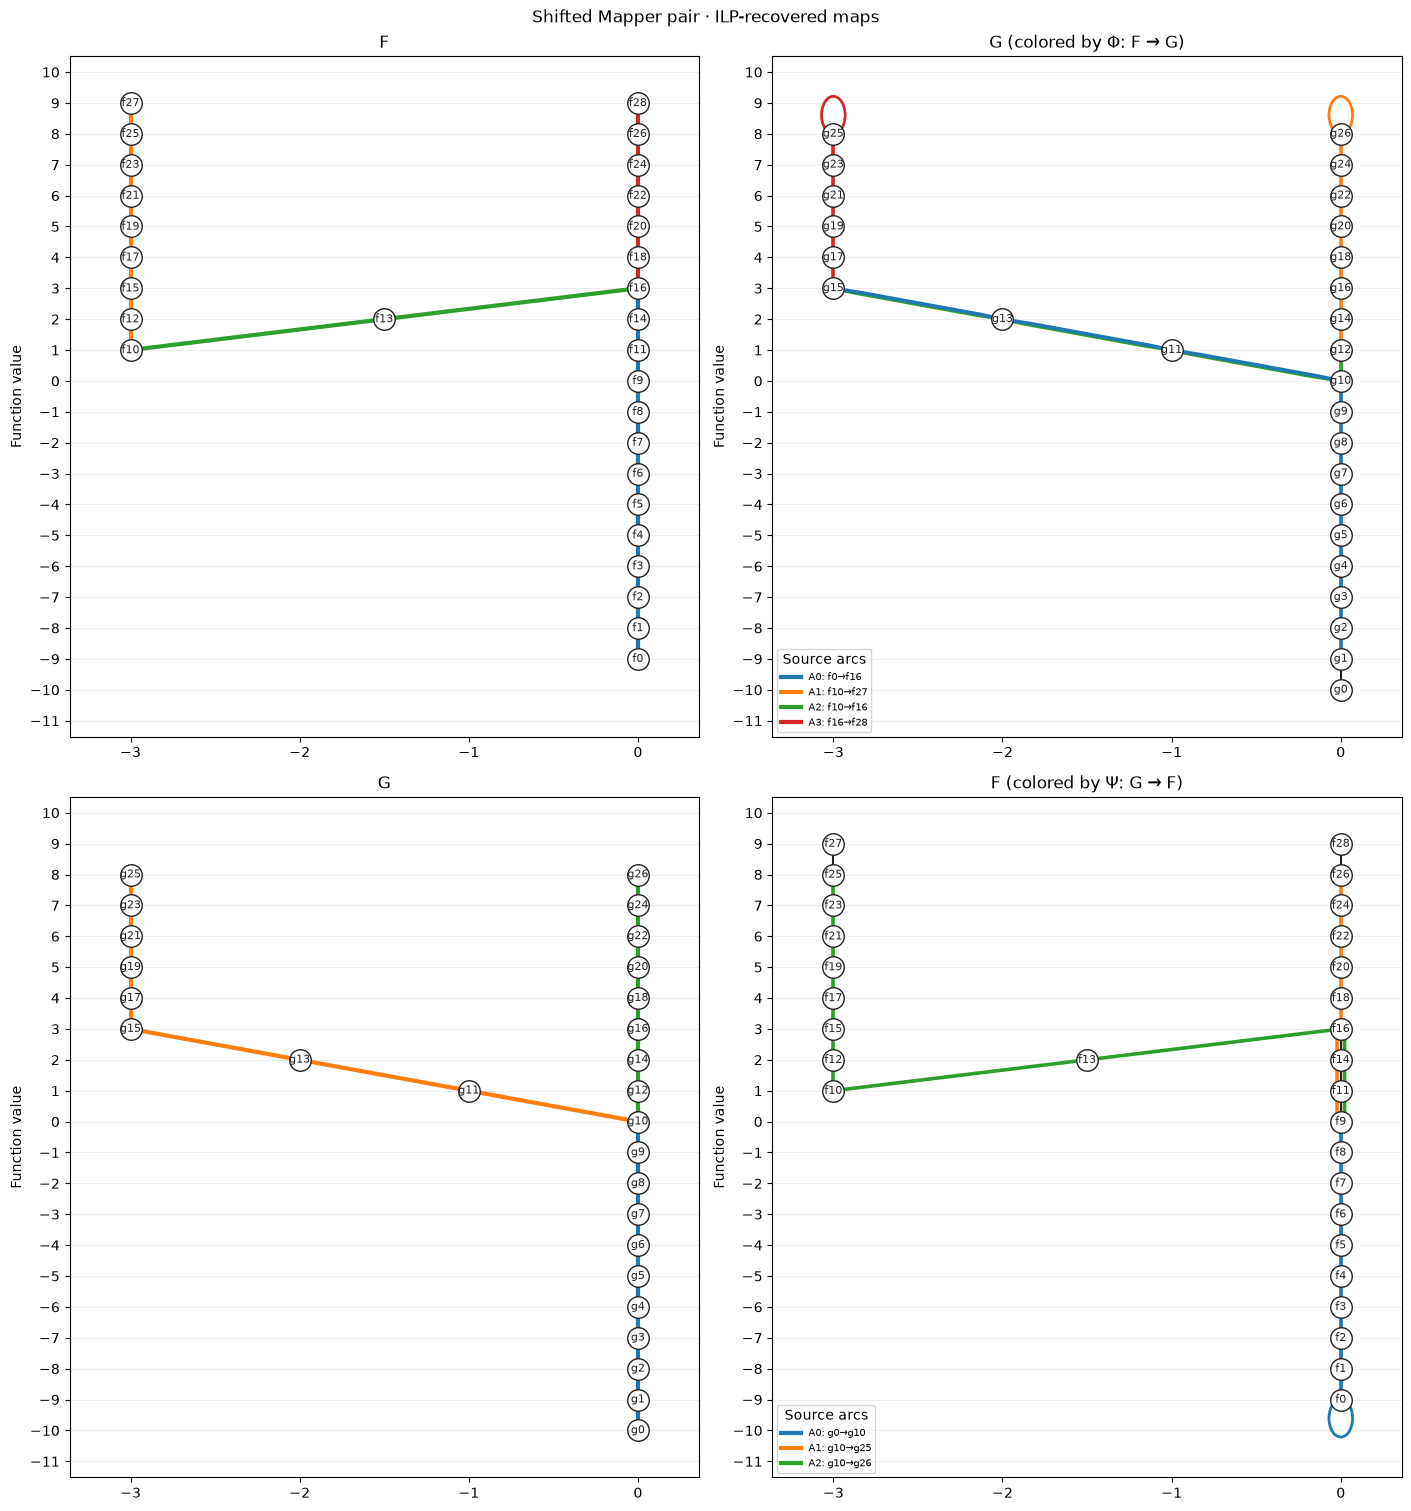

In [ ]:
interleaving, maps, preprocessing, construction = recover_maps(lambda: known_pair(factor_three=False))
report(f"Shifted Mapper pair (ILP, n={interleaving.n})", maps["F"], maps["G"], maps["Phi"], maps["Psi"],
       preprocessing, construction)

plot_known_maps(maps, "Shifted Mapper pair · ILP-recovered maps")


### Hand-built maps

The forward map lowers heights by one. The reverse map raises heights by one except during a short transition along one edge of $G$. During that transition it follows the upper hook of $F$. The figure shows the maps for $\epsilon=0.1$.

Shifted Mapper pair (hand-built, ε=0.1) — Elapsed time: total 0.606 s (preprocessing: 0.012 s, FD map construction: 0.001 s, distortion computation: 0.593 s)
Height Φ = 1.000 | Height Ψ = 1.080 | D = 1.000 | FD = 1.080
Shifted Mapper pair (hand-built, ε=0.01) — Elapsed time: total 0.651 s (preprocessing: 0.012 s, FD map construction: 0.001 s, distortion computation: 0.638 s)
Height Φ = 1.000 | Height Ψ = 1.008 | D = 1.000 | FD = 1.008


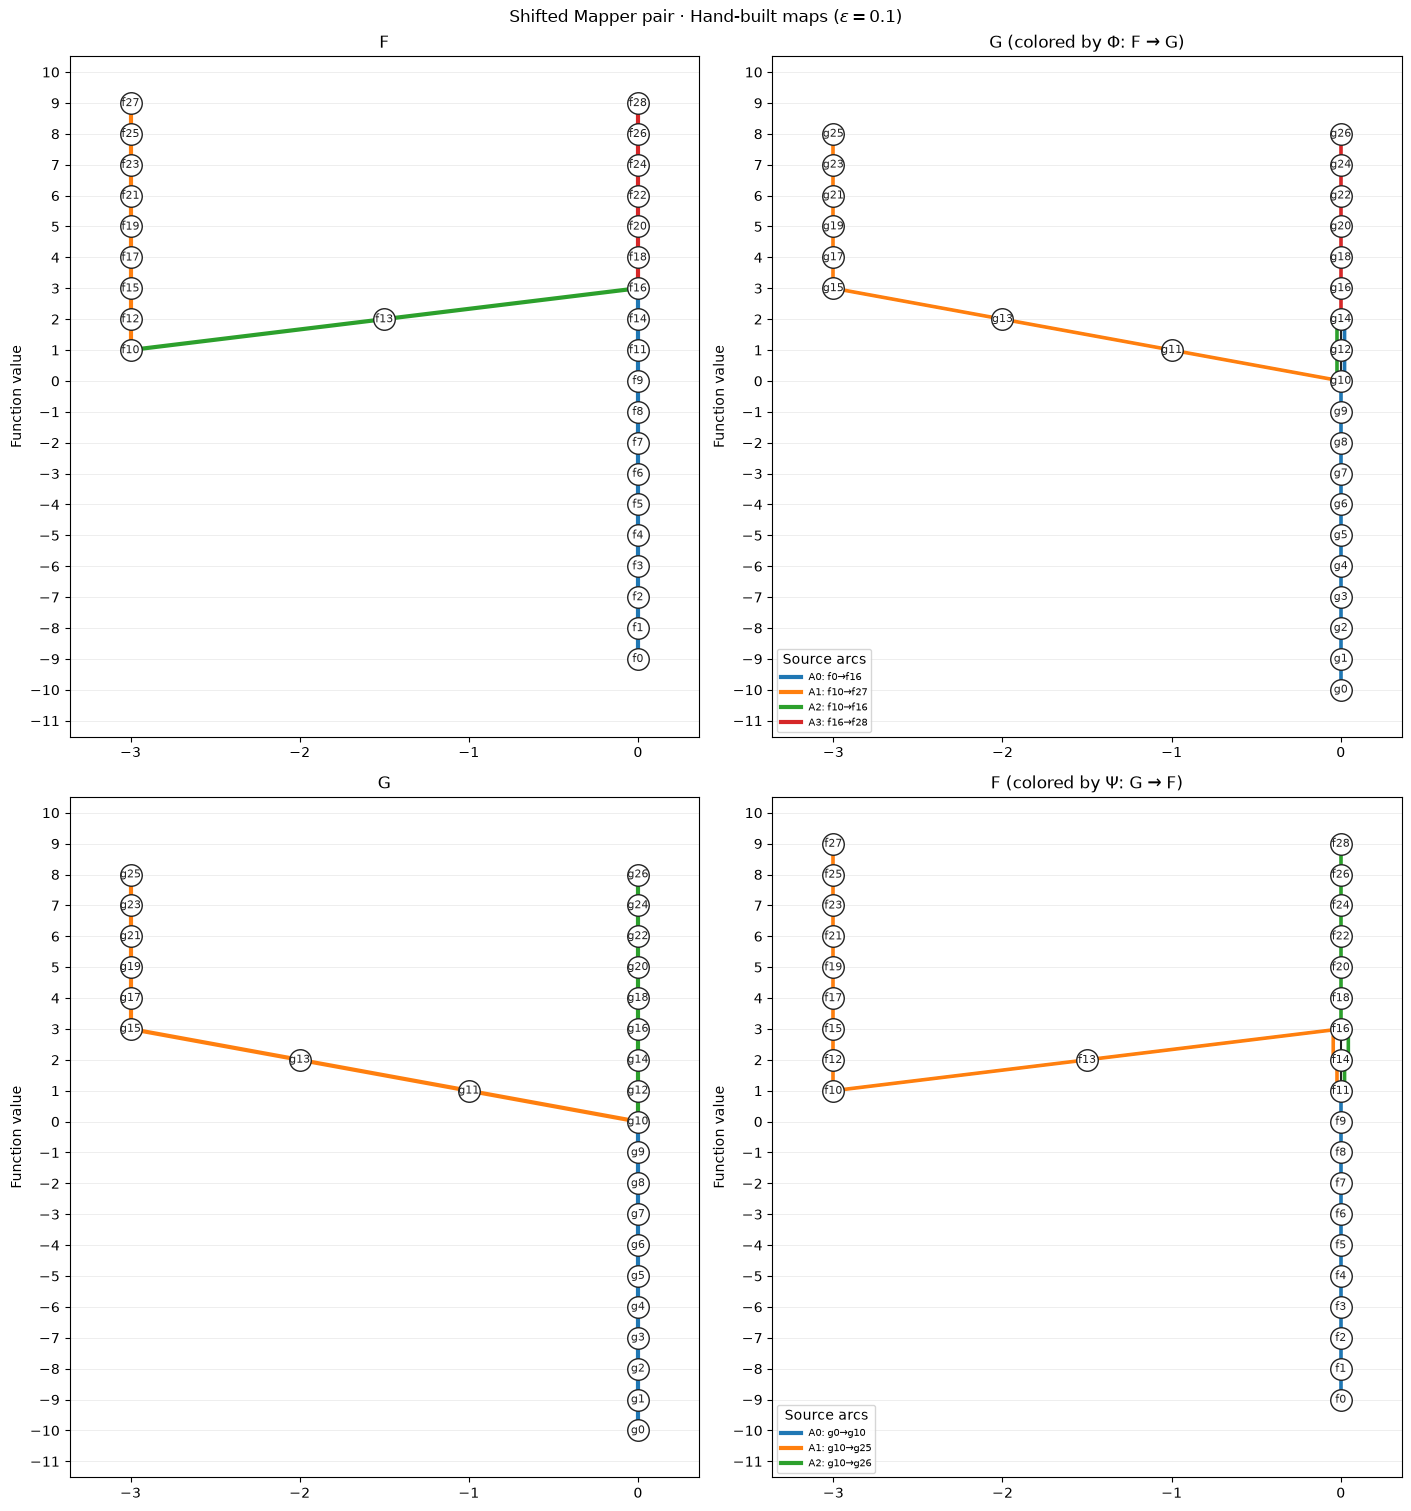

In [ ]:
start = perf_counter()
F, G = (FunctionalDistortionGraph(graph) for graph in known_pair(factor_three=False))
preprocessing = perf_counter() - start
for eps in (Fraction(1, 10), Fraction(1, 100)):
    start = perf_counter()
    forward = {(branch, t): ("G1" if branch == "F1" and t > 1 else "G2", t - 1)
               for branch, t in F.f}
    reverse = {(branch, t): ("F1" if branch == "G1" and t >= 2 else "F3", t + 1)
               for branch, t in G.f}
    transition = (("G1", 1), ("G1", 2))
    route = [E((("F3", 2), ("F3", 3)), 3 - eps),
             ("F3", 3), ("F2", 2), ("F1", 1), ("F1", 2)]
    times = [1 - eps + i * eps / len(route) for i in range(len(route))]
    Phi = F.map_to(G, forward)
    Psi = G.map_to(F, reverse, {transition: route}, {transition: times})
    construction = perf_counter() - start
    report(f"Shifted Mapper pair (hand-built, ε={float(eps):g})", F, G, Phi, Psi, preprocessing, construction)

    if eps == Fraction(1, 10):
        illustrated_maps = {"F": F, "G": G, "Phi": Phi, "Psi": Psi}

plot_known_maps(illustrated_maps, r"Shifted Mapper pair · Hand-built maps ($\epsilon=0.1$)")


In the reverse map, the transition reaches height $3$ in $F$ at source height $2-4\epsilon/5$. This gives the maximum height error $1+4\epsilon/5$, so the scores shown are $1.080$ and $1.008$. As $\epsilon$ shrinks, the scores approach the lower bound $1$. Hence $d_{FD}=1$.

## An added branch

$F$ is a line from height $0$ to $6$. We form $G$ by adding a branch from height $3$ to $5$. This example shows how an edit can change FD distances even when both recovered maps preserve height.

In [ ]:
def added_branch_pair():
    """Return a line and its copy with a branch from height 3 to 5."""
    F = glued_intervals([("F3", 0, 6)], [])
    G = glued_intervals(
        [("G2", 0, 6), ("G1", 3, 5)], [(("G1", 3), ("G2", 3))]
    )
    return F, G


interleaving, maps, preprocessing, construction = recover_maps(added_branch_pair)
F, G = maps["F"], maps["G"]
Phi, Psi = maps["Phi"], maps["Psi"]
result = report(
    f"Added branch (ILP, n={interleaving.n})",
    F, G, Phi, Psi, preprocessing, construction,
)
witness = result["witness_D"]


Added branch (ILP, n=1) — Elapsed time: total 0.145 s (preprocessing: 0.126 s, FD map construction: 0.015 s, distortion computation: 0.004 s)
Height Φ = 0.000 | Height Ψ = 0.000 | D = 1.000 | FD = 1.000


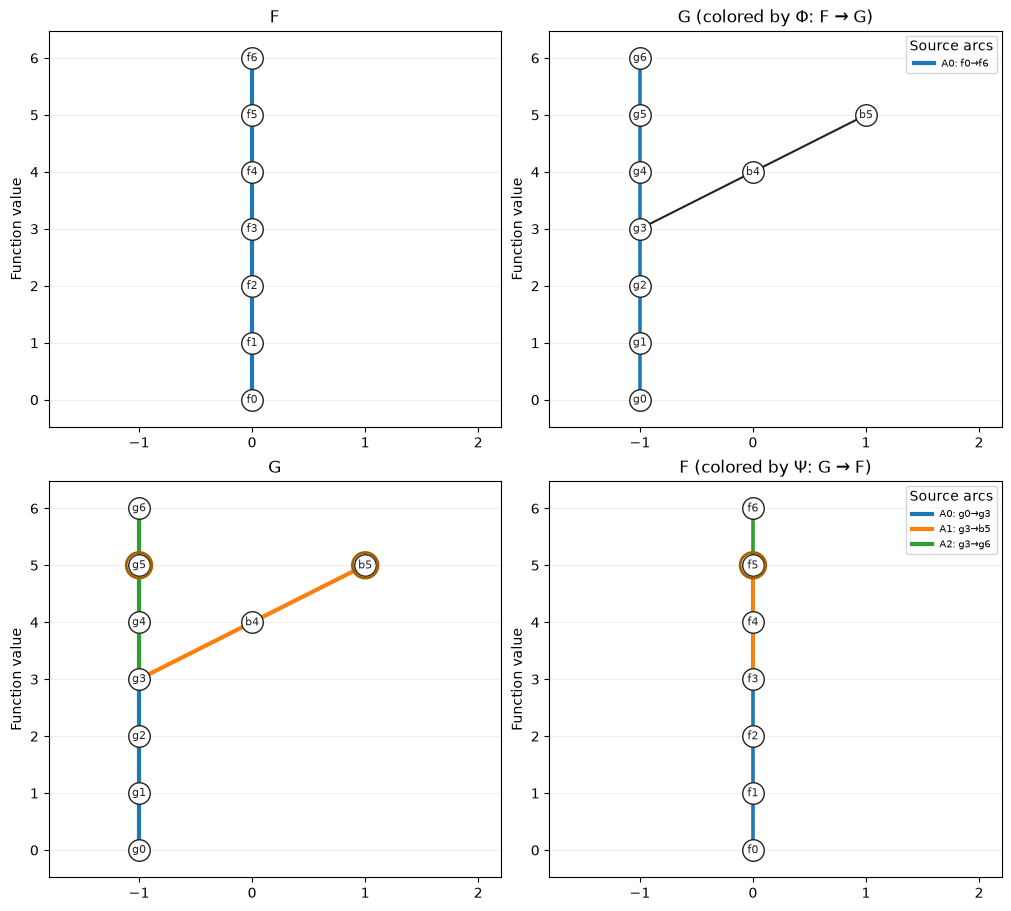

In [ ]:
pos_f = {vertex: (0, height) for vertex, height in F.f.items()}
pos_g = {vertex: (height - 4 if vertex[0] == "G1" else -1, height)
         for vertex, height in G.f.items()}
labels = {"F3": "f", "G2": "g", "G1": "b"}

fig = draw_fd_maps(
    Phi, Psi, posF=pos_f, posG=pos_g, show_vertmaps=False, show_breakpoints=False,
    vertex_label=lambda vertex: f"{labels[vertex[0]]}{vertex[1]}",
    figsize=(10, 9),
)
for ax in fig.axes:
    ax.set_xlim(-1.8, 2.2)

source, target = fig.axes[2:]
for ax, positions, points in (
    (source, pos_g, {y[1] for _, y in witness["pair"]}),
    (target, pos_f, {x[1] for x, _ in witness["pair"]}),
):
    xs, ys = zip(*(positions[vertex] for vertex in points))
    ax.scatter(xs, ys, s=340, facecolors="none", edgecolors="#a65f00", linewidths=2, zorder=8)
plt.show()


In the bottom row, the two circled points in $G$ have the same image in $F$. Their path in $G$ drops from height $5$ to the fork at height $3$, giving $d_G=2$ and $d_F=0$. This accounts for $D=\mathrm{FD}=1$, with zero height error in both directions.